In [1]:
from pennylane import numpy as np
import pennylane as qml
import itertools
from itertools import combinations
from scipy.optimize import minimize
from math import comb
import qaoa_aux 

In [2]:
hyperedge_list = [
    [0, 1, 2, 3],
    [1,4]
]
n_wires = 5
num_layers = 1
seed = 42
example_weights = [1,2]

rng = np.random.default_rng(seed)

edge_list = qaoa_aux.clique_expansion(hyperedge_list)
cost_terms =  qaoa_aux.build_cost_terms(hyperedge_list,example_weights)

In [5]:
print(" (hyperedge_idx, wires, coefficient)")
cost_terms

 (hyperedge_idx, wires, coefficient)


[(0, (0, 1), -0.125),
 (0, (0, 2), -0.125),
 (0, (0, 3), -0.125),
 (0, (1, 2), -0.125),
 (0, (1, 3), -0.125),
 (0, (2, 3), -0.125),
 (0, (0, 1, 2, 3), -0.125),
 (1, (1, 4), -1.0)]

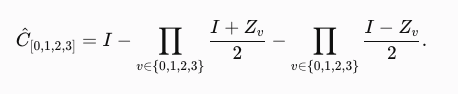

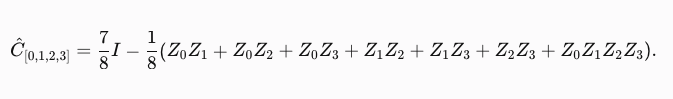

In [10]:
target_weight = n_wires // 2
initial_state = qaoa_aux.make_dicke_state(n_wires, target_weight)
n = int(np.log2(len(initial_state)))

for i, amplitude in enumerate(initial_state):
    if abs(amplitude) > 1e-10:
        bitstring = format(i, f"0{n}b")
        print(f"|{bitstring}⟩ : {amplitude}")

|00011⟩ : (0.31622776601683794+0j)
|00101⟩ : (0.31622776601683794+0j)
|00110⟩ : (0.31622776601683794+0j)
|01001⟩ : (0.31622776601683794+0j)
|01010⟩ : (0.31622776601683794+0j)
|01100⟩ : (0.31622776601683794+0j)
|10001⟩ : (0.31622776601683794+0j)
|10010⟩ : (0.31622776601683794+0j)
|10100⟩ : (0.31622776601683794+0j)
|11000⟩ : (0.31622776601683794+0j)


In [17]:
scaling_constant=0.1
def U_C(gamma,cost_terms):
    # we have term index + cost terms so all the even numbered ZZ's
    for term_idx, (_, wires, coeff) in enumerate(cost_terms):
        theta = 2 * gamma[term_idx] * coeff
        # example for 4 consectuve z's
        #qml.PauliRot(theta, "ZZZZ", wires=[0,1,2,3])
        qml.PauliRot(theta,"Z" * len(wires),wires=list(wires))
def U_B(beta,edge_list):
    for edge_idx, (u, v) in enumerate(edge_list):
        theta = beta[edge_idx]
        qml.S(wires=u)
        qml.SingleExcitationMinus(-2 * theta,wires=[u, v])
        qml.adjoint(qml.S)(wires=u)
dev = qml.device("lightning.qubit",wires=n_wires)
@qml.qnode(dev)
def circuit(gammas, betas):
    qml.StatePrep(initial_state,wires=range(n_wires))

    for layer in range(num_layers):
        U_C(gammas[:, layer],cost_terms)
        U_B(betas[:, layer],edge_list)

    observables = []
    #each observable is a number of Z rotations from cost hamiltonian with fformat:\
    #(hyperedge_idx, wires, coefficient)
    for _, wires, _ in cost_terms:
        z_term = qml.prod(*[qml.PauliZ(wire)for wire in wires])
        observables.append(qml.expval(z_term))
    return observables

# Random parameter initialization
rng = np.random.default_rng(seed)
beta_params = np.array(scaling_constant * rng.random((len(edge_list), num_layers)),requires_grad=True)
gamma_params = np.array(scaling_constant * rng.random((len(cost_terms), num_layers)),requires_grad=True)
circuit(gamma_params,beta_params)

[array(-0.20079703),
 array(-0.19773709),
 array(-0.19808001),
 array(-0.20604396),
 array(-0.20224142),
 array(-0.19557289),
 array(0.2004724),
 array(-0.18468797)]

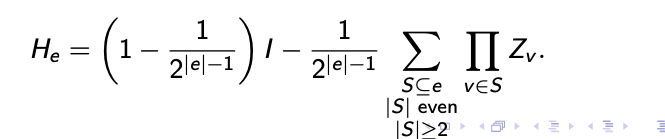

In [18]:
def objective(gammas,betas,circuit,hyperedge_list,cost_terms,weights):
    expectation_values = circuit(gammas, betas)
    value = 0.0

    # weighted constant term for each hyperedge
    for edge_idx, edge in enumerate(hyperedge_list):
        k = len(edge)
        #w_e * 1 - (1/2^k-1)
        value += weights[edge_idx] * (1 - 1 / (2 ** (k - 1)))

    # coeff is weighted in build_cost_terms()
    for term_idx, (_, _, coeff) in enumerate(cost_terms):
        value += coeff * expectation_values[term_idx]

    return value

In [35]:
val= objective(gamma_params,beta_params,circuit,hyperedge_list,cost_terms,example_weights)

In [36]:
print(f"{val:.4f}")

2.1847


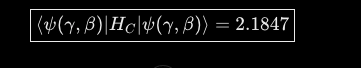

In [22]:
@qml.qnode(dev)
def probability_circuit(gammas, betas):
    qml.StatePrep(initial_state, wires=range(n_wires))

    for layer in range(num_layers):
        U_C(gammas[:, layer], cost_terms)
        U_B(betas[:, layer], edge_list)

    return qml.probs(wires=range(n_wires))

In [24]:
probs = probability_circuit(gamma_params, beta_params)

for i, prob in enumerate(probs):
    if prob > 1e-10:
        bitstring = format(i, f"0{n_wires}b")
        print(f"|{bitstring}⟩ : {float(prob):.6f}")

|00011⟩ : 0.098855
|00101⟩ : 0.099720
|00110⟩ : 0.101870
|01001⟩ : 0.102153
|01010⟩ : 0.097694
|01100⟩ : 0.097883
|10001⟩ : 0.099035
|10010⟩ : 0.101204
|10100⟩ : 0.102430
|11000⟩ : 0.099156


In [37]:
def loss_fn(gammas, betas):
    return objective(gammas,betas,circuit,hyperedge_list,cost_terms,example_weights)


opt = qml.AdamOptimizer(stepsize=0.01)
max_trials = 5

print(f"Initial objective: {float(loss_fn(gamma_params, beta_params)):.6f}")

for iteration in range(max_trials):
    gamma_params, beta_params = opt.step(loss_fn,gamma_params,beta_params)
    current_cost = loss_fn(gamma_params, beta_params)

    print(f"Iteration {iteration + 1}: {float(current_cost):.6f}")

Initial objective: 2.184688
Iteration 1: 2.176577
Iteration 2: 2.166875
Iteration 3: 2.155606
Iteration 4: 2.142785
Iteration 5: 2.128432
